# 🧹 Preprocessing Ulasan Kafe WFC Kota Malang

**Nama :** Fadhli Ilham Nafi'an Yuswono (23.18.001)
**Jurusan :** Teknik Informatika S-1 — Institut Teknologi Nasional Malang
**Penelitian :** Nafinder — Rekomendasi Kafe WFC Kota Malang dengan Multinomial Naive Bayes

**Input :** `ulasan_wfc_final.csv`
**Output :** `label_otomatis.csv`, `dataset_preprocessed.csv`, `contoh_enam_tahap_preprocessing.csv`, `ringkasan_preprocessing.json`, dan file PNG grafik.

> Jalankan sel berurutan dari atas ke bawah. Setiap sel yang menghasilkan file langsung mengunduhnya karena runtime Colab bisa putus kapan saja.

Tahap preprocessing mengikuti Bagian 3.8 laporan: **1 Cleaning, 2 Case Folding, 3 Tokenizing, 4 Normalization, 5 Stopword Removal, 6 Stemming**.


## 📥 IMPORT LIBRARY & UTILITAS

In [13]:
import re, json, glob, os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

def ribu(n):
    """Format angka gaya Indonesia: 109.778"""
    return f"{n:,}".replace(",", ".")

def simpan(fig, nama):
    """Simpan dan unduh grafik di sel yang sama."""
    fig.savefig(nama, bbox_inches="tight")
    try:
        files.download(nama)
    except Exception as e:
        print("Download dilewati (bukan Colab):", e)

# Warna mengikuti makna sentimen
# negatif = merah, netral = biru, positif = hijau
WARNA_SENTIMEN = {"negatif": "#C0392B", "netral": "#2980B9", "positif": "#27AE60"}
URUT_SENTIMEN = ["negatif", "netral", "positif"]
URUT_ASPEK = ["makanan_minuman", "pelayanan", "harga", "suasana", "fasilitas_wfc", "kebersihan"]

print("✅ Libraries imported successfully!")


✅ Libraries imported successfully!


## 📂 LOAD DATASET

In [14]:
uploaded = files.upload()
nama = list(uploaded.keys())[0]
assert nama == "ulasan_wfc_final.csv", f"Upload ulasan_wfc_final.csv, bukan {nama!r}"

df = pd.read_csv(nama, encoding="utf-8-sig").reset_index(drop=True)
for k in ["placeId", "nama_kafe", "teks_ulasan", "rating_ulasan", "tanggal_ulasan", "kafe_id", "valid"]:
    assert k in df.columns, f"Kolom wajib {k!r} tidak ditemukan"

df["review_id"] = df.index
print(f"✅ Dataset loaded successfully!")
print(f"📊 Data: {len(df):,} ulasan | {df['kafe_id'].nunique()} kafe")


Saving ulasan_wfc_final.csv to ulasan_wfc_final.csv
✅ Dataset loaded successfully!
📊 Data: 109,778 ulasan | 324 kafe


## 🔍 FILTER ULASAN VALID

In [15]:
df["valid"] = df["valid"].astype(str).str.lower().eq("true")
n_awal = len(df)
df = df[df["valid"]].copy().reset_index(drop=True)
n_ulasan_awal, n_valid = n_awal, len(df)

per_kafe = df.groupby("nama_kafe").size().sort_values(ascending=False)
print(f"📊 Ulasan valid: {len(df):,} dari {n_awal:,} ({len(df)/n_awal:.1%})")
print(f"📊 Kafe: {df['nama_kafe'].nunique()} | rata-rata ulasan per kafe: {ribu(round(per_kafe.mean()))}")
print(f"📊 Median: {ribu(int(per_kafe.median()))} | terbanyak: {ribu(int(per_kafe.max()))} ({per_kafe.index[0]})")


📊 Ulasan valid: 98,962 dari 109,778 (90.1%)
📊 Kafe: 320 | rata-rata ulasan per kafe: 309
📊 Median: 151 | terbanyak: 2.586 (Kopi Studio 24)


## ✂️ POTONG TEMPLATE GOOGLE MAPS

📊 Ulasan jadi kosong setelah template dipotong: 66
📊 Sisa ulasan: 98,896 dari 98,962


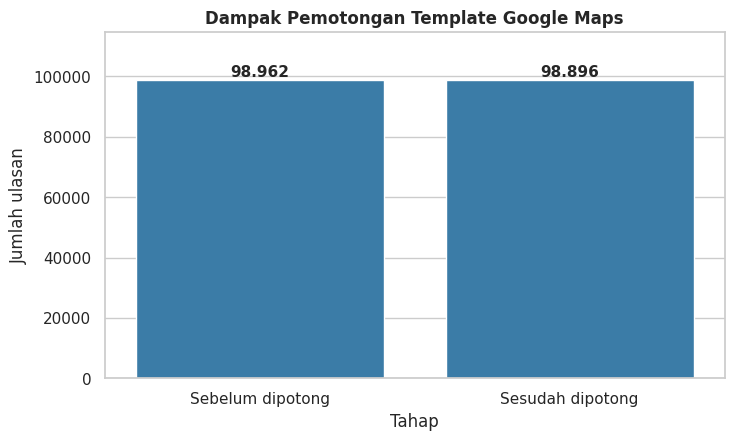

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
PENANDA_TEMPLATE = re.compile(
    r"(?:Jenis pesanan|Jenis makanan|Jenis tempat|Tarif per orang|Waktu tunggu|"
    r"Makanan:\s*\d|Layanan:\s*\d|Suasana:\s*\d|Tingkat kebisingan|"
    r"Tempat parkir|Opsi tempat parkir|Jenis tempat duduk|"
    r"Kesesuaian|Sumber daya|Fasilitas untuk|"
    r"Aksesibilitas|Layanan pelanggan|Pilihan makanan|Kategori)",
    flags=re.I,
)

def potong_template(teks):
    teks = re.sub(r"\s+", " ", str(teks)).strip()
    m = PENANDA_TEMPLATE.search(teks)
    if m:
        teks = teks[:m.start()].strip()
    return teks

n0 = len(df)
df["teks_ulasan"] = df["teks_ulasan"].map(potong_template)
kosong = df["teks_ulasan"].str.strip().eq("")
print(f"📊 Ulasan jadi kosong setelah template dipotong: {kosong.sum():,}")
df = df[~kosong].copy().reset_index(drop=True)
n_setelah_template = len(df)
print(f"📊 Sisa ulasan: {len(df):,} dari {n0:,}")

fig, ax = plt.subplots(figsize=(8, 4.5))
data = pd.DataFrame({"Tahap": ["Sebelum dipotong", "Sesudah dipotong"], "Jumlah": [n0, len(df)]})
sns.barplot(data=data, x="Tahap", y="Jumlah", color="#2980B9", ax=ax)
for b in ax.patches:
    ax.text(b.get_x() + b.get_width()/2, b.get_height(), ribu(int(b.get_height())),
            ha="center", va="bottom", fontweight="bold", fontsize=11)
ax.set_ylabel("Jumlah ulasan")
ax.set_ylim(0, n0 * 1.16)
ax.set_title("Dampak Pemotongan Template Google Maps", fontweight="bold")
plt.show()
simpan(fig, "grafik_03_template_dipotong.png")


## 💬 PECAH ULASAN MENJADI SUB-KALIMAT

📊 Ulasan valid : 98,896
📊 Sub-kalimat  : 230,281


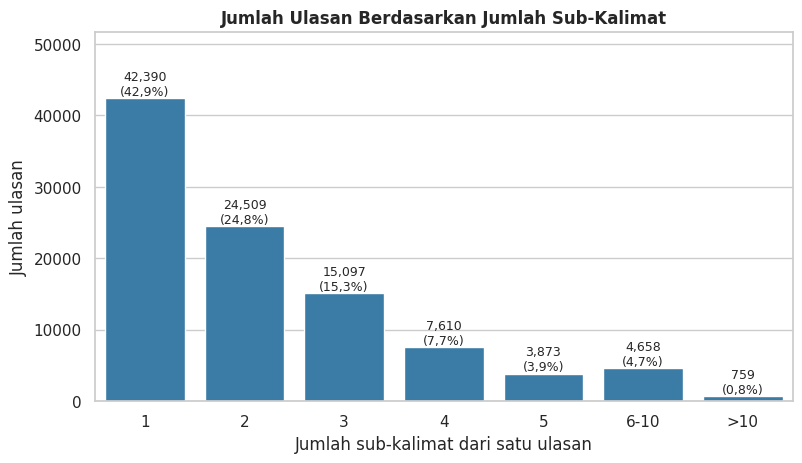

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
PECAH_BAGIAN = re.compile(
    r",\s*|\s+(?:tapi|namun|tetapi|padahal|meski|walaupun|sedangkan|however|although)\s+",
    flags=re.I,
)
# \t di sini karakter tab sungguhan (bukan string dua karakter backslash + t)
TAHAN_BERSIH = " ;:.!?\t\"'“”‘’"

def pecah_subkalimat(teks):
    teks = re.sub(r"\s+", " ", str(teks)).strip()
    potongan = [p.strip(TAHAN_BERSIH) for p in PECAH_BAGIAN.split(teks)]
    return [p for p in potongan if p]

baris = []
for r in df.itertuples():
    for p in pecah_subkalimat(r.teks_ulasan):
        baris.append({
            "review_id": r.review_id, "placeId": r.placeId, "nama_kafe": r.nama_kafe,
            "kafe_id": r.kafe_id, "rating_ulasan": r.rating_ulasan,
            "sub_kalimat": p, "asal_sub_kalimat": r.teks_ulasan,
        })
sub = pd.DataFrame(baris)
print(f"📊 Ulasan valid : {df['review_id'].nunique():,}")
print(f"📊 Sub-kalimat  : {len(sub):,}")

per_ulasan = sub.groupby("review_id").size()

def kelompokkan(n):
    return str(n) if n <= 5 else ("6-10" if n <= 10 else ">10")

urutan = ["1", "2", "3", "4", "5", "6-10", ">10"]
hitung = per_ulasan.map(kelompokkan).value_counts().reindex(urutan).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(9, 4.8))
data = pd.DataFrame({"Sub-kalimat": urutan, "Jumlah ulasan": hitung.values})
sns.barplot(data=data, x="Sub-kalimat", y="Jumlah ulasan", color="#2980B9", ax=ax)
for b in ax.patches:
    v = int(b.get_height())
    persen = v / len(per_ulasan) * 100
    ax.text(b.get_x() + b.get_width()/2, v, f"{ribu(v)}\n({persen:.1f}%)".replace(".", ","),
            ha="center", va="bottom", fontsize=9)
ax.set_xlabel("Jumlah sub-kalimat dari satu ulasan")
ax.set_ylabel("Jumlah ulasan")
ax.set_ylim(0, hitung.max() * 1.22)
ax.set_title("Jumlah Ulasan Berdasarkan Jumlah Sub-Kalimat", fontweight="bold")
plt.show()
simpan(fig, "grafik_04_subkalimat_per_ulasan.png")


## 🏷️ PELABELAN APEK & SENTIMEN OTOMATIS

### 📐 Lexicon Sentimen Nafinder

Kata ditambah hanya jika lolos tiga syarat: (a) ada di InSet dan/atau SentiStrength-Id ATAU terbukti dari korpus ulasan sendiri, (b) di korpus minimal 75% baris searah dan rating rata-rata searah, (c) tidak ambigu di konteks kafe WFC.

Sumber: InSet (Koto et al., 2016) & SentiStrength-Id (Wahid & Azhari, 2016), diverifikasi pada korpus ulasan kafe Kota Malang. Negasi tiga token ke belakang membalik polaritas.


In [18]:
POSITIF = {
    "enak","nikmat","mantap","bagus","nyaman","ramah","cepat","recommended","rekomendasi","suka","puas",
    "fresh","segar","worth","oke","ok","berkesan","rapi","bersih","murah","terjangkau","favorit","favorite",
    "great","good","delicious","nice","cozy","clean","helpful","friendly","affordable","amazing","perfect",
    "instagramable","love","best","satisfied",
    "lezat","mantul","uenak","wenak","gurih","creamy","sedap","harum","wangi","worthit",
    "asri","teduh","sejuk","adem","luas","lega","lapang","homey","asik","seru","kece","keren",
    "aesthetic","cantik","indah",
    "sigap","responsif","tanggap","bersahabat",
    "lengkap","komplit","memadai","hemat","juara","menarik","menyenangkan","senang","bahagia",
    "membantu","perhatian","terbaik",
}

NEGATIF = {
    "jelek","kecewa","lambat","mahal","ketus","kotor","bau","pahit","antri","antre","jorok","berisik",
    "overpriced","expensive","bad","disappointed","dirty","slow","cold","stale","mengecewakan",
    "sembarangan","panas","sumpek","sesak","lama","ribet","susah","quite high","kemahalan","hambar",
    "dingin","tidak ramah","not worth","poor","worst","percuma","jutek",
    "basi","gosong","amis",
    "judes","lelet","lemot",
    "kacau",
    "buruk","kesal","sebal","benci","nyebelin","nyeselin","kesel","ngeselin","parahnya",
    "enek","eneg",
}

# Kata yang ditolak: ada di lexicon luar tapi ambigu di konteks kafe
TOLAK = {
    "parah", "sepi", "penuh", "padat", "bising", "sulit", "repot", "pengap", "gerah", "bocor", "rusak",
    "berantakan","tawar","garing","pecah","sopan","peduli","malang","biasa","cukup",
    "pelayanan","pelayan","pelayanannya","duduk","pesanan","tempat",
}

NEGASI = {
    "tidak","bukan","belum","jangan","tanpa","gak","gk","nggak","enggak","tdk","kurang","anti",
    "ga","blm","blum","jgn","ngga","engga","gajadi","belom",
}

def skor_sentimen(teks):
    """Skor leksikon pada satu bagian teks. Negasi tiga token ke belakang membalik polaritas."""
    tokens = re.findall(r"[a-zA-Z']+", str(teks).lower())
    skor = 0
    for i, tok in enumerate(tokens):
        if tok in TOLAK:
            continue
        neg = any(n in tokens[max(0, i-3):i] for n in NEGASI)
        if tok in POSITIF:
            skor += -1 if neg else 1
        elif tok in NEGATIF:
            skor += 1 if neg else -1
    return skor

def label_sentimen(teks, rating):
    """Skor leksikon dulu; rating hanya cadangan ketika skor nol.

    Aturan fallback: rating 5 positif, rating 1 negatif, selain itu netral.
    """
    s = skor_sentimen(teks)
    if s > 0: return "positif"
    if s < 0: return "negatif"
    if rating is not None and rating == rating:
        if rating >= 5: return "positif"
        if rating <= 1: return "negatif"
    return "netral"

print("✅ Lexicon sentimen siap.")


✅ Lexicon sentimen siap.


In [19]:
# Aspek penelitian dan kata kunci lexicon
KATA_ASPEK = {
    "makanan_minuman": ["kopi", "coffee", "makanan", "minuman", "menu", "rasa", "enak", "beans", "biji", "latte", "matcha", "cokelat", "croissant", "roti", "kue", "cake", "dessert", "susu", "milk", "teh", "tea", "jus", "juice", "nasi", "mie", "pasta", "pizza", "segar", "fresh", "manis", "pahit", "asin", "pedas", "gurih", "piccolo", "cappuccino", "espresso", "americano", "mocha", "croffle", "fried rice", "kopi susu", "iced coffee", "hot chocolate"],
    "pelayanan": ["pelayanan", "service", "staff", "petugas", "pegawai", "kasir", "ramah", "ketus", "sopan", "waiter", "waitress", "servis", "respon", "ramahnya", "orangnya", "kindness", "friendly", "antri", "antre", "cs", "dilayani", "pelanggan", "lambat", "slow", "jutek", "takeaway"],
    "harga": ["harga", "price", "murah", "mahal", "worth", "terjangkau", "budget", "bayar", "rupiah", "kemahalan", "price range", "affordable", "expensive", "overpriced", "cheap", "charge", "kisaran harga", "quite high", "rp", "idr", "cukup mahal", "terlalu mahal"],
    "suasana": ["suasana", "ambience", "atmosphere", "vibe", "nyaman", "tempat", "dekor", "konsep", "aesthetic", "musik", "ramai", "sepi", "crowd", "pemandangan", "view", "panorama", "crowded", "cozy", "hangout", "spot", "foto", "instagramable", "tenang", "berisik", "kursi", "meja", "interior", "privat"],
    "fasilitas_wfc": ["wifi", "internet", "stopkontak", "colokan", "charging", "plug", "laptop", "kerja", "work", "wfh", "wfc", "meeting", "24 jam", "buka 24", "parkir", "parking", "mushola", "toilet", "workspace", "power", "sinyal", "bekerja", "kerjaan"],
    "kebersihan": ["bersih", "kotor", "kebersihan", "debu", "higienis", "sanitasi", "clean", "dirty", "hygiene", "lantai", "meja kotor", "bau", "jorok", "rapi", "hand sanitizer"],
}

def deteksi_aspek(teks):
    t = f" {teks.lower()} "
    return [a for a, kata in KATA_ASPEK.items() if any(k.strip() in t for k in kata)]

baris, tanpa_aspek = [], 0
for r in sub.itertuples():
    aspek_list = deteksi_aspek(r.sub_kalimat)
    if not aspek_list:
        tanpa_aspek += 1
        continue
    sentimen = label_sentimen(r.sub_kalimat, r.rating_ulasan)
    for aspek in aspek_list:
        baris.append({
            "review_id": r.review_id, "placeId": r.placeId, "nama_kafe": r.nama_kafe,
            "kafe_id": r.kafe_id, "rating_ulasan": r.rating_ulasan,
            "sub_kalimat": r.sub_kalimat, "asal_sub_kalimat": r.asal_sub_kalimat,
            "aspek": aspek, "sentimen": sentimen,
        })

label = pd.DataFrame(baris)
print(f"📊 Sub-kalimat  : {len(sub):,}")
print(f"📊 Tanpa aspek  : {tanpa_aspek:,} (tidak dilabeli)")
print(f"📊 Total label  : {len(label):,}")
print(f"📊 Review unik  : {label['review_id'].nunique():,}")

# berapa banyak yang ditentukan teks, bukan rating
skor = label["sub_kalimat"].map(skor_sentimen)
print(f"\n📊 Label dari teks (skor != 0)  : {(skor!=0).sum():,} ({(skor!=0).mean():.1%})")
print(f"📊 Label dari rating (skor == 0): {(skor==0).sum():,} ({(skor==0).mean():.1%})")

print("\nDistribusi aspek:")
display(label["aspek"].value_counts().to_frame("Jumlah"))
print("Distribusi sentimen:")
display(label["sentimen"].value_counts().reindex(URUT_SENTIMEN).fillna(0).astype(int).to_frame("Jumlah"))
print("Sentimen per aspek (%):")
display((pd.crosstab(label["aspek"], label["sentimen"], normalize="index")*100).round(1))


📊 Sub-kalimat  : 230,281
📊 Tanpa aspek  : 59,469 (tidak dilabeli)
📊 Total label  : 240,676
📊 Review unik  : 88,194

📊 Label dari teks (skor != 0)  : 168,127 (69.9%)
📊 Label dari rating (skor == 0): 72,549 (30.1%)

Distribusi aspek:


,Jumlah
aspek,
makanan_minuman,86369
suasana,76221
pelayanan,28070
harga,23350
fasilitas_wfc,17335
kebersihan,9331


Distribusi sentimen:


,Jumlah
sentimen,
negatif,19920
netral,23073
positif,197683


Sentimen per aspek (%):


sentimen,negatif,netral,positif
aspek,,,
fasilitas_wfc,10.4,13.3,76.3
harga,9.8,9.6,80.5
kebersihan,13.9,8.9,77.2
makanan_minuman,7.3,11.2,81.4
pelayanan,16.4,7.3,76.2
suasana,4.7,7.8,87.5


### 📊 1. DISTRIBUSI APEK & SENTIMEN

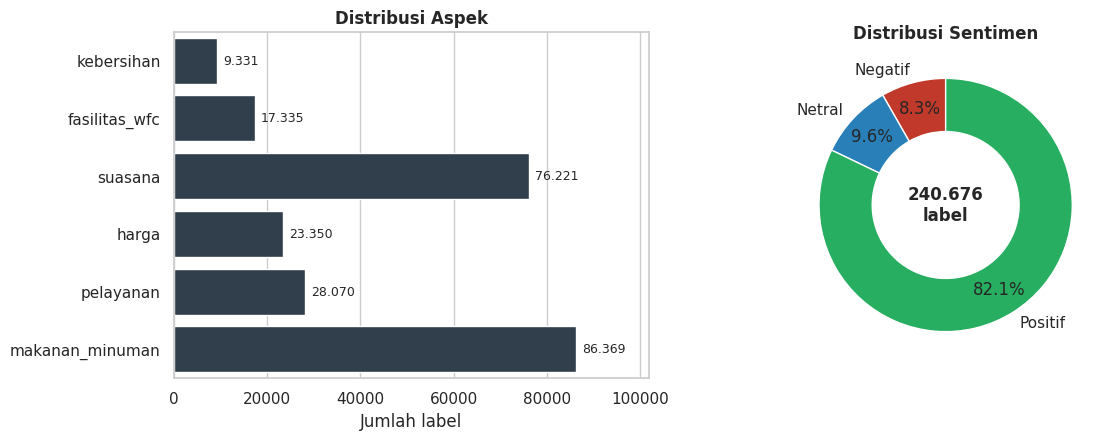

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
urut_aspek = label["aspek"].value_counts().reindex(URUT_ASPEK)
urut_sent = label["sentimen"].value_counts().reindex(URUT_SENTIMEN).fillna(0).astype(int)

fig = plt.figure(figsize=(12, 4.5))
gs = fig.add_gridspec(1, 2, width_ratios=[1.5, 1], wspace=0.35)

ax1 = fig.add_subplot(gs[0, 0])
data_aspek = pd.DataFrame({"Aspek": URUT_ASPEK[::-1], "Jumlah label": urut_aspek.values[::-1]})
sns.barplot(data=data_aspek, x="Jumlah label", y="Aspek", color="#2C3E50", ax=ax1)
for b in ax1.patches:
    ax1.text(b.get_width() + urut_aspek.max()*0.015, b.get_y() + b.get_height()/2,
             ribu(int(b.get_width())), va="center", fontsize=9)
ax1.set_title("Distribusi Aspek", fontweight="bold")
ax1.set_xlim(0, urut_aspek.max() * 1.18)
ax1.set_ylabel("")
ax1.grid(axis="y", visible=False)

ax2 = fig.add_subplot(gs[0, 1])
ax2.pie(urut_sent.values, labels=urut_sent.index.str.capitalize(), autopct="%.1f%%",
        startangle=90, pctdistance=0.79,
        colors=[WARNA_SENTIMEN[k] for k in urut_sent.index],
        wedgeprops=dict(width=0.42, edgecolor="white"))
ax2.set_title("Distribusi Sentimen", fontweight="bold")
ax2.text(0, 0, f"{ribu(len(label))}\nlabel", ha="center", va="center", fontweight="bold")
plt.show()
simpan(fig, "grafik_05_distribusi_aspek_sentimen.png")


### 📊 2. KOMPOSISI SENTIMEN PADA TIAP APEK

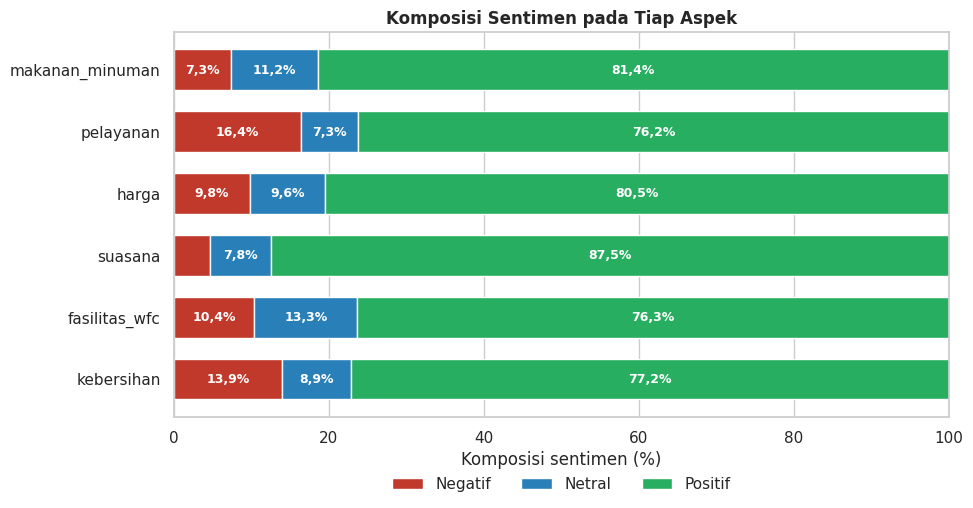

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
prop = ((pd.crosstab(label["aspek"], label["sentimen"], normalize="index") * 100)
        .reindex(index=URUT_ASPEK, columns=URUT_SENTIMEN))

fig, ax = plt.subplots(figsize=(10, 5))
kiri = np.zeros(len(URUT_ASPEK))
for kelas in URUT_SENTIMEN:
    v = prop[kelas].values
    ax.barh(URUT_ASPEK, v, left=kiri, height=0.66,
            color=WARNA_SENTIMEN[kelas], label=kelas.capitalize())
    for i, (vv, kk) in enumerate(zip(v, kiri)):
        if vv >= 7:
            ax.text(kk + vv / 2, i, f"{vv:.1f}%".replace(".", ","),
                    ha="center", va="center", color="white", fontweight="bold", fontsize=9)
    kiri = kiri + v
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Komposisi sentimen (%)")
ax.set_title("Komposisi Sentimen pada Tiap Aspek", fontweight="bold")
ax.legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.grid(axis="y", visible=False)
plt.show()
simpan(fig, "grafik_06_komposisi_sentimen_per_aspek.png")


## 🧹 PREPROCESSING TEKS

Urutan mengikuti Bagian 3.8 laporan: **1 Cleaning, 2 Case Folding, 3 Tokenizing, 4 Normalization, 5 Stopword Removal, 6 Stemming**.


In [22]:
!pip install -q Sastrawi
from IPython.display import display
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

KAMUS_NORMALISASI = {
    "gk":"tidak", "ga":"tidak", "gak":"tidak", "nggak":"tidak", "enggak":"tidak", "tdk":"tidak", "kagak":"tidak",
    "bgt":"sangat", "banget":"sangat", "bener":"benar", "yg":"yang", "dgn":"dengan", "utk":"untuk", "krn":"karena",
    "karna":"karena", "tp":"tapi", "aja":"saja", "jg":"juga", "udh":"sudah", "udah":"sudah", "sdh":"sudah", "blm":"belum",
    "belom":"belum", "dr":"dari", "sm":"sama", "sy":"saya", "klo":"kalau", "kalo":"kalau", "bwt":"buat", "bs":"bisa",
    "org":"orang", "bbrp":"beberapa", "gitu":"begitu", "gini":"begini", "makasih":"terima kasih", "trims":"terima kasih",
    "thx":"terima kasih", "recommended":"rekomendasi", "recomend":"rekomendasi", "worth it":"sepadan", "cozy":"nyaman",
    "resto":"restoran",
    "nget":"", "sih":"", "dong":"", "deh":"", "lah":"", "kah":"","pun":"",
}
NEGASI_DIPERTAHANKAN = {"tidak","bukan","belum","jangan","tanpa","tak","tetapi","namun","tapi","meski","meskipun","walaupun"}
stopwords_sastrawi = set(StopWordRemoverFactory().get_stop_words())
STOPWORDS_FINAL = (stopwords_sastrawi | {"nih","yuk","kok","loh","hehe","wkwk","nya"}) - NEGASI_DIPERTAHANKAN

stemmer = StemmerFactory().create_stemmer()
peta_kata = {}

# --- fungsi enam tahap, urutannya sama dengan laporan
def tahap1_cleaning(text):
    text = re.sub(r"http\S+|www\S+", " ", str(text))
    text = re.sub(r"@\w+|#\w+", " ", text)
    text = re.sub(r"[\U0001F300-\U0001FAFF\u2600-\u27bf]", " ", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def tahap2_case_folding(text):
    return text.lower()

def tahap3_tokenizing(text):
    return text.split()

def tahap4_normalisasi(tokens):
    return [KAMUS_NORMALISASI.get(t, t) for t in tokens]

def tahap5_stopword(tokens):
    return [t for t in tokens if t and t not in STOPWORDS_FINAL]

def tahap6_stemming(tokens):
    return [peta_kata.get(t, t) for t in tokens]

# --- kamus stemming dibuat sekali dari kata unik
kata_unik = set()
for teks in label["sub_kalimat"]:
    t = tahap2_case_folding(tahap1_cleaning(teks))
    for w in tahap5_stopword(tahap4_normalisasi(tahap3_tokenizing(t))):
        if len(w) >= 3:
            kata_unik.add(w)
kata_unik = sorted(kata_unik)

print(f"📊 Baris label      : {len(label):,}")
print(f"📊 Kata unik distem : {len(kata_unik):,}")
for i, k in enumerate(kata_unik, 1):
    peta_kata[k] = stemmer.stem(k)
    if i % 5000 == 0 or i == len(kata_unik):
        print(f"{i:,}/{len(kata_unik):,} kata selesai", flush=True)

def preprocess_teks(teks):
    t = tahap2_case_folding(tahap1_cleaning(teks))
    toks = tahap5_stopword(tahap4_normalisasi(tahap3_tokenizing(t)))
    return " ".join(w for w in tahap6_stemming(toks) if len(w) >= 3)

label["teks_preprocessed"] = label["sub_kalimat"].map(preprocess_teks)
n_sebelum_prepro = len(label)
label = label[label["teks_preprocessed"].str.strip() != ""].copy()

print()
print(f"📊 Data masuk           : {n_sebelum_prepro:,} label")
print(f"📊 Data keluar          : {len(label):,} label")
print(f"📊 Dibuang (teks kosong): {n_sebelum_prepro - len(label):,}")


📊 Baris label      : 240,676
📊 Kata unik distem : 35,927
5,000/35,927 kata selesai
10,000/35,927 kata selesai
15,000/35,927 kata selesai
20,000/35,927 kata selesai
25,000/35,927 kata selesai
30,000/35,927 kata selesai
35,000/35,927 kata selesai
35,927/35,927 kata selesai

📊 Data masuk           : 240,676 label
📊 Data keluar          : 240,636 label
📊 Dibuang (teks kosong): 40


### 📋 TABEL CONTOH — SATU ULASAN DITELUSURI ENAM TAHAP

In [23]:
CONTOH = ("Cabang Nakoa yang paling enak byat wfc dan nongki karena gak se-crowded "
          "cabang lainnya \U0001F643" + "Jenis pesananMakan di tempatJenis makananMakan malam"
          "Tarif per orangRp 25\u201350 rbRekomendasi hidanganEs Kopi Susu Aren")
CONTOH_SUB = potong_template(CONTOH)

def jalankan_enam_tahap(raw):
    t1 = tahap1_cleaning(raw)
    t2 = tahap2_case_folding(t1)
    t3 = tahap3_tokenizing(t2)
    t4 = tahap4_normalisasi(t3)
    t5 = tahap5_stopword(t4)
    t6 = tahap6_stemming(t5)
    akhir = [w for w in t6 if len(w) >= 3]
    return pd.DataFrame([
        ("1. Cleaning", t1, len(t1.split())),
        ("2. Case Folding", t2, len(t2.split())),
        ("3. Tokenizing", " | ".join(t3), len(t3)),
        ("4. Normalization", " | ".join(t4), len(t4)),
        ("5. Stopword Removal", " | ".join(t5), len(t5)),
        ("6. Stemming", " | ".join(akhir), len(akhir)),
    ], columns=["Tahap", "Hasil", "Jumlah Kata"])

tabel_tahap = jalankan_enam_tahap(CONTOH_SUB)
tabel_tahap.to_csv("contoh_enam_tahap_preprocessing.csv", index=False, encoding="utf-8-sig")
try:
    files.download("contoh_enam_tahap_preprocessing.csv")
except Exception as e:
    print("Download dilewati:", e)
display(tabel_tahap)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,Tahap,Hasil,Jumlah Kata
0,1. Cleaning,Cabang Nakoa yang paling enak byat wfc dan non...,15
1,2. Case Folding,cabang nakoa yang paling enak byat wfc dan non...,15
2,3. Tokenizing,cabang | nakoa | yang | paling | enak | byat |...,15
3,4. Normalization,cabang | nakoa | yang | paling | enak | byat |...,15
4,5. Stopword Removal,cabang | nakoa | paling | enak | byat | wfc | ...,12
5,6. Stemming,cabang | nakoa | paling | enak | byat | wfc | ...,11


## 📈 VISUALISASI HASIL PREPROCESSING

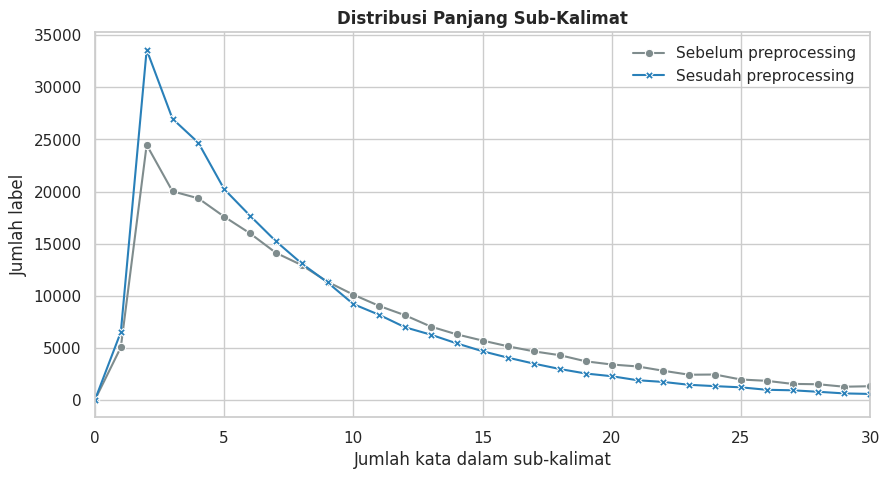

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
label["panjang_awal"] = label["sub_kalimat"].str.split().str.len()
label["panjang_akhir"] = label["teks_preprocessed"].str.split().str.len()

batas = np.arange(0, 31)
kurva_sebelum = [int((label["panjang_awal"] == b).sum()) for b in batas]
kurva_akhir = [int((label["panjang_akhir"] == b).sum()) for b in batas]

data_garis = pd.DataFrame({
    "Jumlah kata": np.concatenate([batas, batas]),
    "Jumlah label": kurva_sebelum + kurva_akhir,
    "Tahap": ["Sebelum preprocessing"]*len(batas) + ["Sesudah preprocessing"]*len(batas),
})

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=data_garis, x="Jumlah kata", y="Jumlah label", hue="Tahap",
             style="Tahap", markers=True, dashes=False, ax=ax,
             palette={"Sebelum preprocessing": "#7F8C8D", "Sesudah preprocessing": "#2980B9"})
ax.set_title("Distribusi Panjang Sub-Kalimat", fontweight="bold")
ax.set_xlabel("Jumlah kata dalam sub-kalimat")
ax.set_ylabel("Jumlah label")
ax.set_xlim(0, 30)
ax.legend(frameon=False)
plt.show()
simpan(fig, "grafik_09_panjang_teks_sebelum_sesudah.png")


## 🔝 KATA PALING SERING MUNCUL

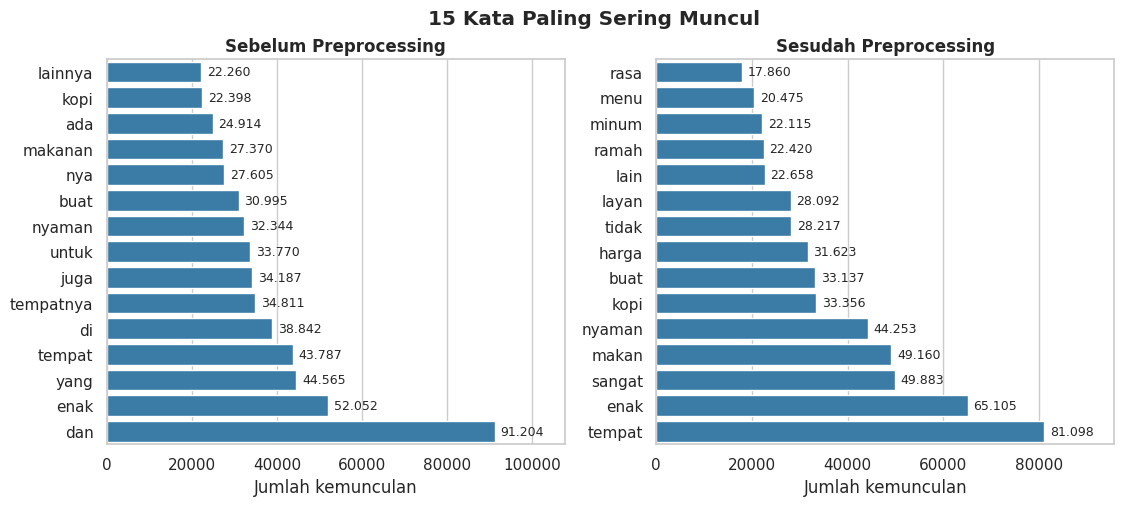

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

📊 Sisa template pada teks model: 28 (target 0)


In [25]:
from collections import Counter

def kata_teratas(seri, n=15):
    c = Counter()
    for t in seri.dropna():
        c.update(str(t).lower().split())
    return pd.Series(dict(c.most_common(n)))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, data, judul in [(axes[0], kata_teratas(label["sub_kalimat"]), "Sebelum Preprocessing"),
                        (axes[1], kata_teratas(label["teks_preprocessed"]), "Sesudah Preprocessing")]:
    d = data.iloc[::-1]
    sns.barplot(x=d.values, y=d.index, color="#2980B9", ax=ax)
    for i, v in enumerate(d.values):
        ax.text(v + d.max()*0.015, i, ribu(int(v)), va="center", fontsize=9)
    ax.set_title(judul, fontweight="bold")
    ax.set_xlabel("Jumlah kemunculan")
    ax.set_ylabel("")
    ax.set_xlim(0, d.max()*1.18)
    ax.grid(axis="y", visible=False)
fig.suptitle("15 Kata Paling Sering Muncul", fontweight="bold")
plt.show()
simpan(fig, "grafik_10_kata_teratas.png")

sisa = label["teks_preprocessed"].str.contains(
    r"jenis makanan|tarif orang|kebisingan|waktu tunggu|berbayar", regex=True).sum()
print(f"📊 Sisa template pada teks model: {sisa} (target 0)")


## ✅ VALIDASI LABEL

✅ Validasi label: lolos


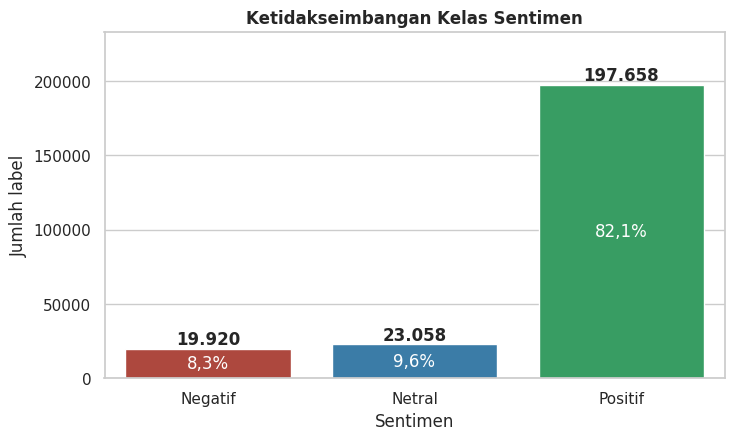

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
ASPEK_VALID = set(URUT_ASPEK)
SENTIMEN_VALID = {"positif", "negatif", "netral"}

assert not (set(label["aspek"]) - ASPEK_VALID)
assert not (set(label["sentimen"]) - SENTIMEN_VALID)
assert label["aspek"].ne("").all() and label["sentimen"].ne("").all()
assert label["sub_kalimat"].str.strip().ne("").all()
assert label["review_id"].notna().all()
for a in ASPEK_VALID:
    kelas = set(label.loc[label["aspek"] == a, "sentimen"])
    assert kelas == SENTIMEN_VALID, f"Aspek {a} kehilangan kelas: {SENTIMEN_VALID - kelas}"
print("✅ Validasi label: lolos")

sebelum = label["sentimen"].value_counts().reindex(URUT_SENTIMEN).fillna(0).astype(int)
data_sent = pd.DataFrame({
    "Sentimen": [k.capitalize() for k in URUT_SENTIMEN],
    "Jumlah label": sebelum.values,
    "warna": [WARNA_SENTIMEN[k] for k in URUT_SENTIMEN],
})
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=data_sent, x="Sentimen", y="Jumlah label", hue="Sentimen",
            palette={k.capitalize(): WARNA_SENTIMEN[k] for k in URUT_SENTIMEN},
            legend=False, ax=ax)
for b, k in zip(ax.patches, URUT_SENTIMEN):
    h = b.get_height()
    ax.text(b.get_x() + b.get_width()/2, h, ribu(int(h)),
            ha="center", va="bottom", fontweight="bold")
    ax.text(b.get_x() + b.get_width()/2, h/2,
            f"{h / sebelum.sum() * 100:.1f}%".replace(".", ","),
            ha="center", va="center", color="white")
ax.set_ylabel("Jumlah label")
ax.set_ylim(0, sebelum.max() * 1.18)
ax.set_title("Ketidakseimbangan Kelas Sentimen", fontweight="bold")
plt.show()
simpan(fig, "grafik_08_ketidakseimbangan_kelas.png")


## 💾 SIMPAN LABEL

In [27]:
NAMA_LABEL = "label_otomatis.csv"
label.to_csv(NAMA_LABEL, index=False, encoding="utf-8-sig")
print(f"✅ Tersimpan: {NAMA_LABEL} ({len(label):,} label)")
files.download(NAMA_LABEL)


✅ Tersimpan: label_otomatis.csv (240,636 label)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 💾 SIMPAN DATASET FINAL

In [28]:
keluaran = label[[
    "review_id", "placeId", "nama_kafe", "kafe_id", "rating_ulasan",
    "sub_kalimat", "asal_sub_kalimat", "aspek", "sentimen", "teks_preprocessed",
]].reset_index(drop=True)

NAMA_OUT = "dataset_preprocessed.csv"
keluaran.to_csv(NAMA_OUT, index=False, encoding="utf-8-sig")

print(f"📊 Data final : {len(keluaran):,} label")
print(f"📊 Review unik: {keluaran['review_id'].nunique():,}")
print(f"📊 Kafe       : {keluaran['kafe_id'].nunique()}")
print(f"✅ Tersimpan  : {NAMA_OUT}")
files.download(NAMA_OUT)


📊 Data final : 240,636 label
📊 Review unik: 88,189
📊 Kafe       : 323
✅ Tersimpan  : dataset_preprocessed.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 📉 PERPINDAHAN DATA

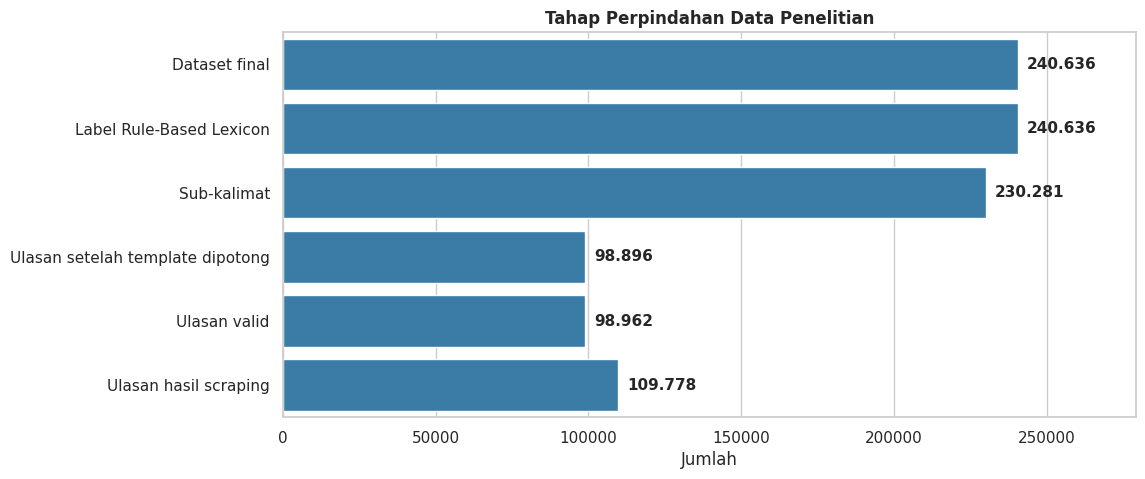

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

{
  "Ulasan hasil scraping": 109778,
  "Ulasan valid": 98962,
  "Ulasan setelah template dipotong": 98896,
  "Sub-kalimat": 230281,
  "Label Rule-Based Lexicon": 240636,
  "Dataset final": 240636
}


In [29]:
FUNNEL_FINAL = {
    "Ulasan hasil scraping": n_ulasan_awal,
    "Ulasan valid": n_valid,
    "Ulasan setelah template dipotong": n_setelah_template,
    "Sub-kalimat": len(sub),
    "Label Rule-Based Lexicon": len(label),
    "Dataset final": len(label),
}

data_funnel = pd.DataFrame({
    "Tahap": list(FUNNEL_FINAL.keys())[::-1],
    "Jumlah": list(FUNNEL_FINAL.values())[::-1],
})
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=data_funnel, x="Jumlah", y="Tahap", color="#2980B9", ax=ax)
for b in ax.patches:
    ax.text(b.get_width() + max(FUNNEL_FINAL.values())*0.012,
            b.get_y() + b.get_height()/2,
            ribu(int(b.get_width())), va="center", fontweight="bold", fontsize=11)
ax.set_xlabel("Jumlah")
ax.set_xlim(0, max(FUNNEL_FINAL.values()) * 1.16)
ax.set_title("Tahap Perpindahan Data Penelitian", fontweight="bold")
ax.set_ylabel("")
ax.grid(axis="y", visible=False)
plt.show()
simpan(fig, "grafik_11_funnel_final.png")

with open("ringkasan_preprocessing.json", "w", encoding="utf-8") as f:
    json.dump(FUNNEL_FINAL, f, ensure_ascii=False, indent=2)
try:
    files.download("ringkasan_preprocessing.json")
except Exception as e:
    print("Download dilewati:", e)
print(json.dumps(FUNNEL_FINAL, ensure_ascii=False, indent=2))


## 🖼️ PAPAN RINGKAS

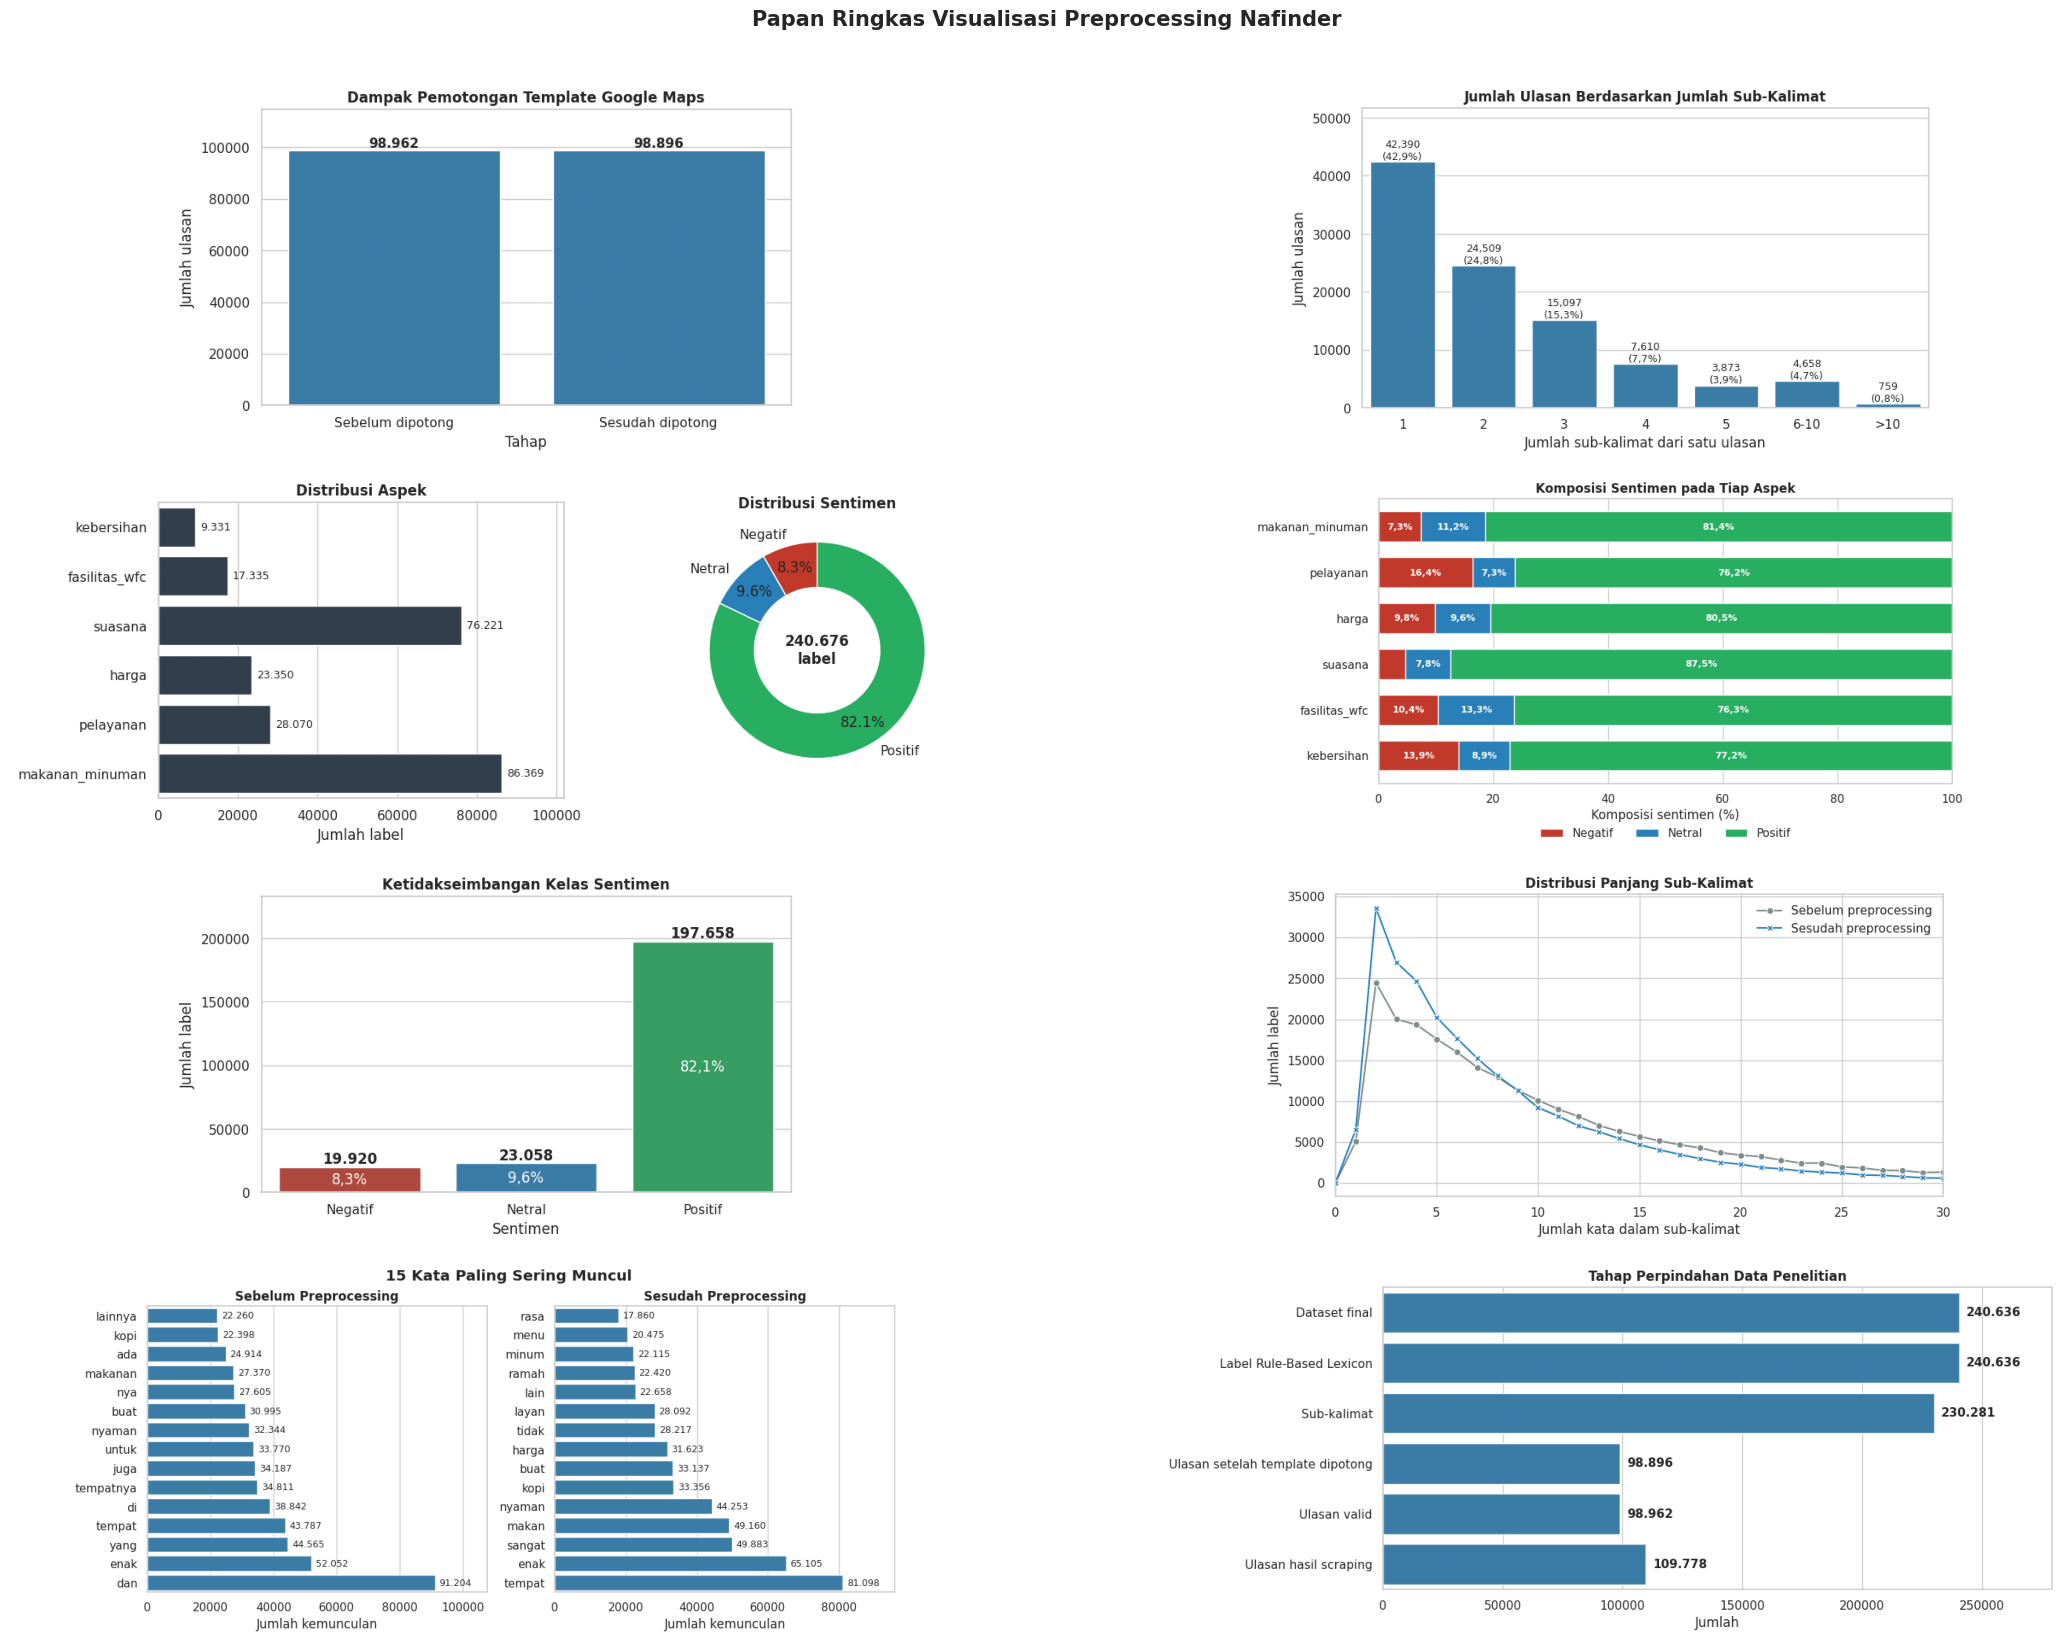

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
from matplotlib.image import imread

daftar = sorted(glob.glob("grafik_*.png"))
if not daftar:
    print("Belum ada grafik. Jalankan sel visualisasi terlebih dahulu.")
else:
    n = len(daftar); kol = 2; baris = (n + kol - 1) // kol
    fig, axes = plt.subplots(baris, kol, figsize=(12.5 * kol, 4.2 * baris))
    axes = list(np.atleast_1d(axes).ravel())
    for ax, path in zip(axes, daftar):
        ax.imshow(imread(path))
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle("Papan Ringkas Visualisasi Preprocessing Nafinder",
                 fontsize=15, fontweight="bold")
    plt.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()
    simpan(fig, "papan_ringkas_preprocessing.png")
